
# Task 2: Feature Extraction and Image Matching

## Objective
To extract image features using Histogram of Oriented Gradients (HOG) and Scale-Invariant Feature Transform (SIFT), match features between two photographs, and study how image rotation affects matching.

## Methods
1. Histogram of Oriented Gradients (HOG)
2. SIFT keypoint and descriptor extraction
3. Brute-Force feature matching
4. Feature matching after image rotation



In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from skimage.feature import hog

print("All libraries imported successfully!")
print("OpenCV version:", cv2.__version__)

All libraries imported successfully!
OpenCV version: 4.10.0


In [2]:
print("Original image exists:",
      os.path.exists("dataset/original.jpg"))

print("Second image exists:",
      os.path.exists("dataset/second.jpg"))

os.makedirs("outputs", exist_ok=True)

Original image exists: True
Second image exists: True


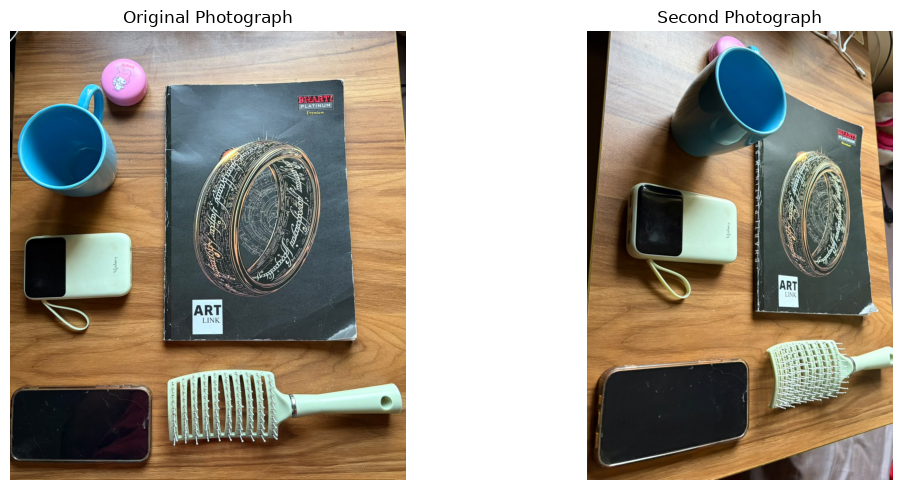

First image dimensions: (1280, 1130, 3)
Second image dimensions: (1280, 872, 3)


In [3]:
# Load the first photograph
image1_bgr = cv2.imread("dataset/original.jpg")

# Load the second photograph
image2_bgr = cv2.imread("dataset/second.jpg")

# Convert BGR to RGB for correct display
image1 = cv2.cvtColor(image1_bgr, cv2.COLOR_BGR2RGB)
image2 = cv2.cvtColor(image2_bgr, cv2.COLOR_BGR2RGB)

# Display both photographs
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image1)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image2)
plt.title("Second Photograph")
plt.axis("off")

plt.tight_layout()
plt.show()

print("First image dimensions:", image1.shape)
print("Second image dimensions:", image2.shape)

In [4]:
from skimage.feature import hog

# Convert both photographs to grayscale
gray1 = cv2.cvtColor(image1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_RGB2GRAY)

# Resize both images to the same dimensions
gray1_resized = cv2.resize(gray1, (128, 128))
gray2_resized = cv2.resize(gray2, (128, 128))

# Extract HOG features from the first image
features1, hog_image1 = hog(
    gray1_resized,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

# Extract HOG features from the second image
features2, hog_image2 = hog(
    gray2_resized,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

print("HOG features extracted successfully!")
print("First image HOG feature count:", len(features1))
print("Second image HOG feature count:", len(features2))

HOG features extracted successfully!
First image HOG feature count: 8100
Second image HOG feature count: 8100


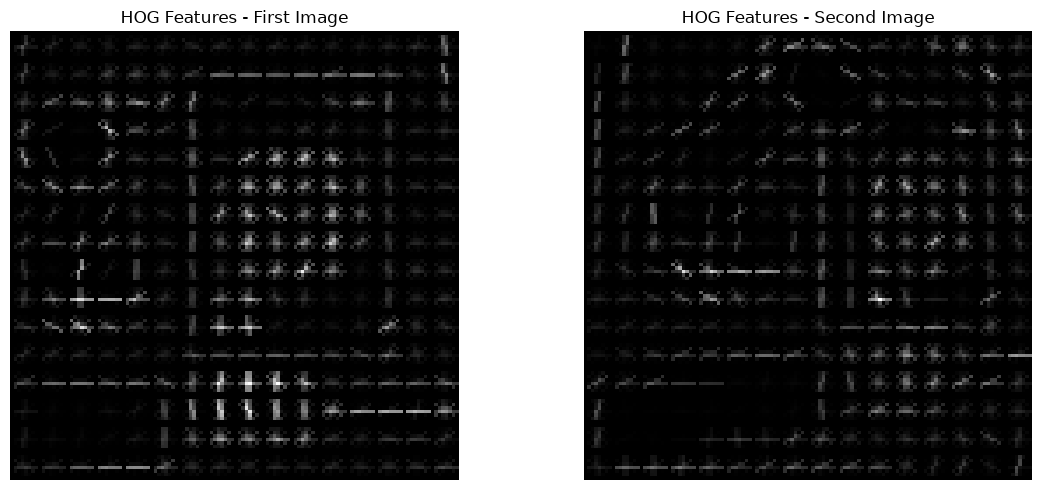

HOG visualizations saved in the outputs folder.


In [5]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(hog_image1, cmap="gray")
plt.title("HOG Features - First Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image2, cmap="gray")
plt.title("HOG Features - Second Image")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.imsave("outputs/hog_image1.png", hog_image1, cmap="gray")
plt.imsave("outputs/hog_image2.png", hog_image2, cmap="gray")

print("HOG visualizations saved in the outputs folder.")

In [6]:
# Create the SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and calculate descriptors
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

# Display the results
print("First image keypoints:", len(keypoints1))
print("Second image keypoints:", len(keypoints2))

print("First image descriptor shape:", descriptors1.shape if descriptors1 is not None else None)
print("Second image descriptor shape:", descriptors2.shape if descriptors2 is not None else None)

First image keypoints: 5347
Second image keypoints: 4013
First image descriptor shape: (5347, 128)
Second image descriptor shape: (4013, 128)


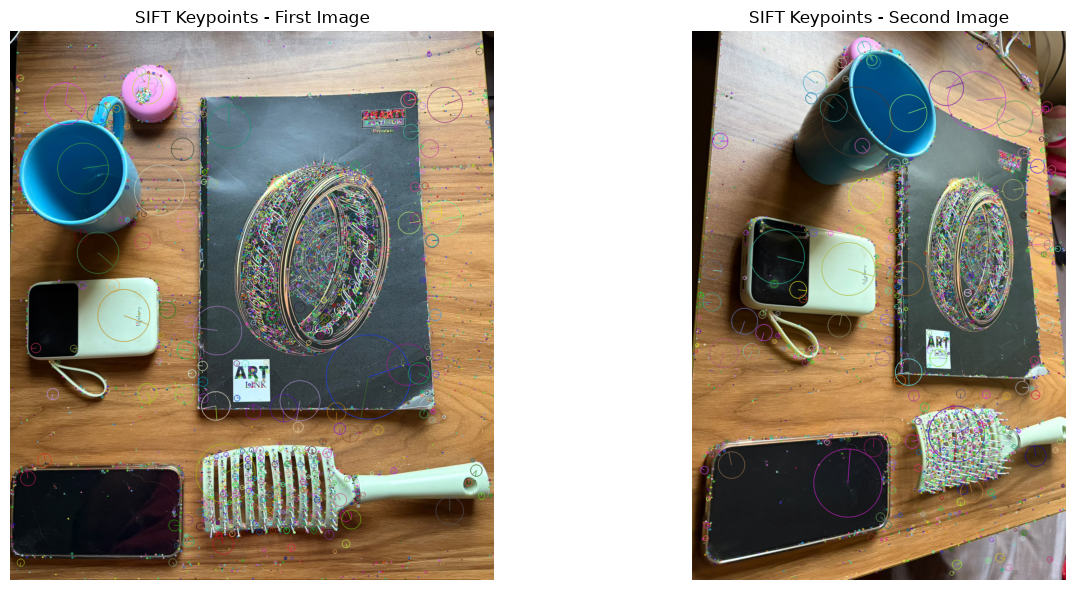

SIFT keypoint images saved successfully!


In [7]:
# Draw keypoints on both photographs
keypoints_image1 = cv2.drawKeypoints(
    image1, keypoints1, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

keypoints_image2 = cv2.drawKeypoints(
    image2, keypoints2, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display the images
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(keypoints_image1)
plt.title("SIFT Keypoints - First Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(keypoints_image2)
plt.title("SIFT Keypoints - Second Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save the results
plt.imsave("outputs/sift_keypoints_image1.png", keypoints_image1)
plt.imsave("outputs/sift_keypoints_image2.png", keypoints_image2)

print("SIFT keypoint images saved successfully!")

In [8]:
# Create a Brute-Force matcher
bf = cv2.BFMatcher()

# Find the two nearest matches for each descriptor
matches = bf.knnMatch(
    descriptors1,
    descriptors2,
    k=2
)

# Keep good matches using Lowe's ratio test
good_matches = []

for pair in matches:
    if len(pair) == 2:
        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

print("Total initial matches:", len(matches))
print("Good feature matches:", len(good_matches))

Total initial matches: 5347
Good feature matches: 341


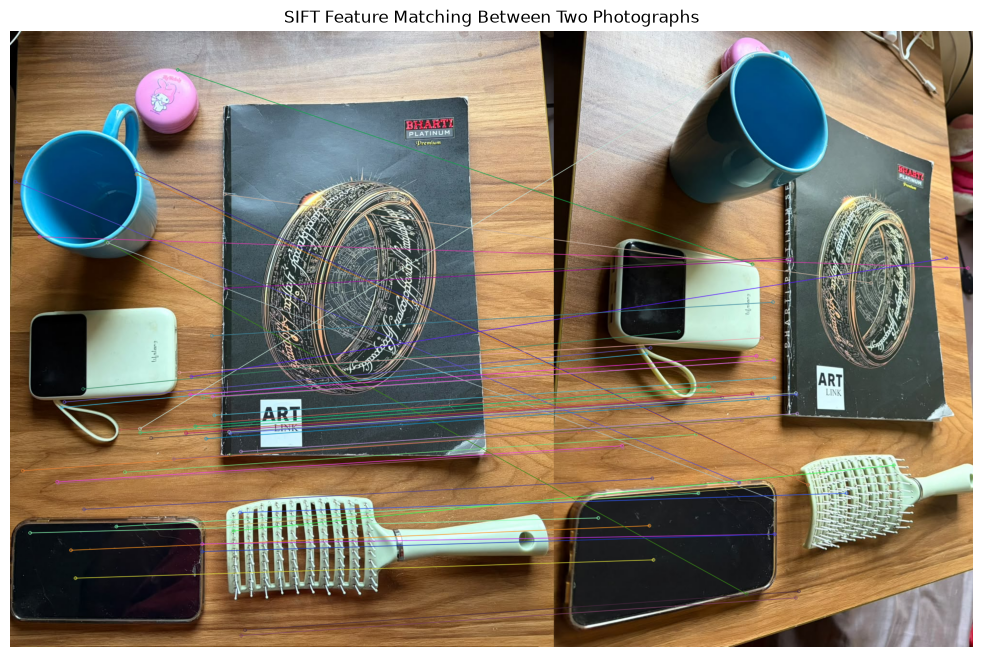

Feature matching result saved successfully!


In [9]:
# Draw up to 50 good feature matches
match_image = cv2.drawMatches(
    image1,
    keypoints1,
    image2,
    keypoints2,
    good_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(match_image)
plt.title("SIFT Feature Matching Between Two Photographs")
plt.axis("off")
plt.show()

# Save the result
cv2.imwrite(
    "outputs/sift_feature_matching.png",
    cv2.cvtColor(match_image, cv2.COLOR_RGB2BGR)
)

print("Feature matching result saved successfully!")

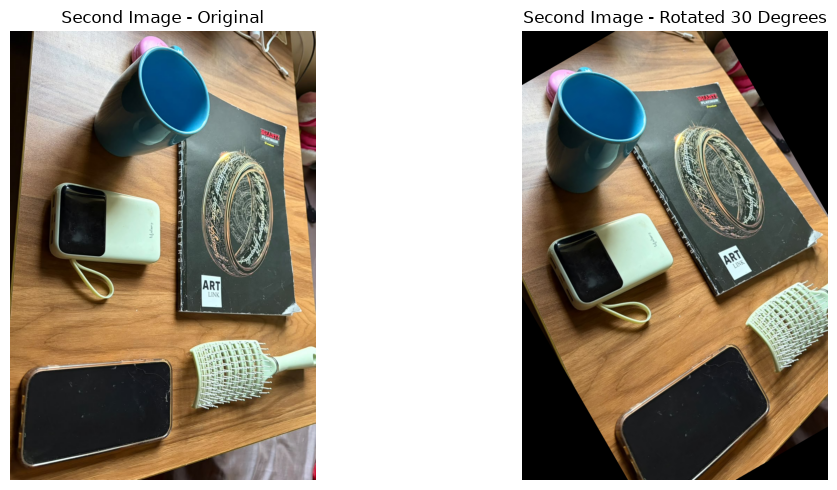

Image rotated and saved successfully!


In [10]:
# Get the dimensions of the second image
height, width = image2.shape[:2]

# Create a rotation matrix for 30 degrees
center = (width // 2, height // 2)

rotation_matrix = cv2.getRotationMatrix2D(
    center, 30, 1.0
)

# Rotate the second image
rotated_image2 = cv2.warpAffine(
    image2,
    rotation_matrix,
    (width, height)
)

# Display the original and rotated images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image2)
plt.title("Second Image - Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_image2)
plt.title("Second Image - Rotated 30 Degrees")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save the rotated image
cv2.imwrite(
    "outputs/rotated_second.jpg",
    cv2.cvtColor(rotated_image2, cv2.COLOR_RGB2BGR)
)

print("Image rotated and saved successfully!")

In [11]:
# Convert the rotated image to grayscale
rotated_gray = cv2.cvtColor(
    rotated_image2, cv2.COLOR_RGB2GRAY
)

# Detect keypoints and descriptors
keypoints_rotated, descriptors_rotated = (
    sift.detectAndCompute(rotated_gray, None)
)

print("Keypoints in original second image:", len(keypoints2))
print("Keypoints in rotated second image:", len(keypoints_rotated))

Keypoints in original second image: 4013
Keypoints in rotated second image: 4126


In [12]:
# Match the first image with the rotated second image
rotated_matches = bf.knnMatch(
    descriptors1,
    descriptors_rotated,
    k=2
)

# Apply Lowe's ratio test
good_rotated_matches = []

for pair in rotated_matches:
    if len(pair) == 2:
        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_rotated_matches.append(m)

print("Good matches before rotation:", len(good_matches))
print("Good matches after rotation:", len(good_rotated_matches))

Good matches before rotation: 341
Good matches after rotation: 319


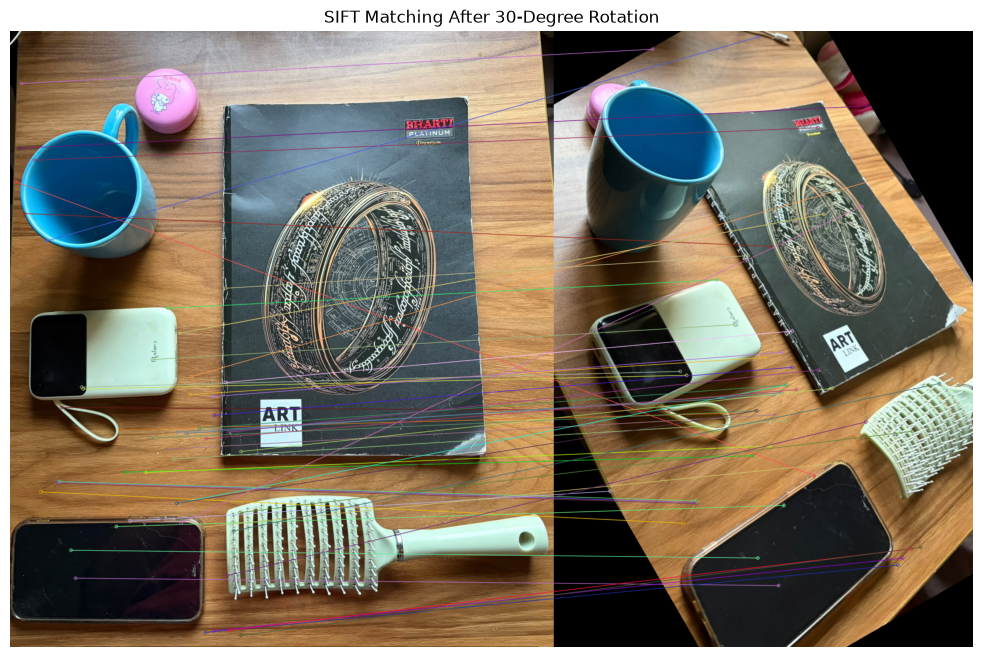

Rotated matching result saved successfully!


In [13]:
# Draw up to 50 good matches
rotated_match_image = cv2.drawMatches(
    image1,
    keypoints1,
    rotated_image2,
    keypoints_rotated,
    good_rotated_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(rotated_match_image)
plt.title("SIFT Matching After 30-Degree Rotation")
plt.axis("off")
plt.show()

# Save the result
cv2.imwrite(
    "outputs/sift_rotated_matching.png",
    cv2.cvtColor(rotated_match_image, cv2.COLOR_RGB2BGR)
)

print("Rotated matching result saved successfully!")


## Results and Observations

### 1. HOG Feature Extraction
HOG was used to extract features based on edge directions and gradient information from both photographs. The HOG visualizations highlight important structural patterns in the images.

### 2. SIFT Keypoint Detection
SIFT detected 4,013 keypoints in the original second photograph and 4,126 keypoints in the rotated photograph. Keypoints represent distinctive locations in an image, while descriptors describe the surrounding features.

### 3. Feature Matching
The Brute-Force Matcher and Lowe's ratio test were used to match SIFT descriptors between the two photographs. The original images produced 341 good matches.

### 4. Matching After Rotation
After rotating the second photograph by 30 degrees, the number of good matches decreased to 319. This is a reduction of 22 matches, or approximately 6.45%.

### Conclusion
HOG helped visualize the structural features of the images, while SIFT detected distinctive keypoints and descriptors. SIFT matching produced 341 good matches before rotation and 319 after rotation. The relatively small decrease suggests that many features remained matchable after rotation. However, the number of matches alone does not establish their accuracy.
